<a href="https://colab.research.google.com/github/1900690/lettuce-analysis/blob/main/lettuce_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- データ確認 ---
抽出された全株数: 216 行
グループ
試験区    108
対照区    108
Name: count, dtype: int64

--- 分析結果サマリー ---


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


,調査項目,試験区 (n),試験区 平均±SD,対照区 (n),対照区 平均±SD,p値,有意差 (p<0.05)
0,草丈,60,16.60 ± 1.69,60,16.91 ± 2.20,0.3917,なし
1,葉数（外）,60,5.00 ± 0.00,60,5.00 ± 0.00,-,なし
2,葉数（内）,60,21.15 ± 4.06,60,21.63 ± 4.75,0.5502,なし
3,球縦径,60,36.78 ± 4.52,60,37.53 ± 5.26,0.4037,なし
4,球横径,60,37.78 ± 3.70,60,38.07 ± 4.22,0.6963,なし
5,球重量,60,420.01 ± 103.36,60,459.00 ± 129.47,0.0710,なし
6,食害葉数（全部）,60,10.27 ± 4.97,60,11.92 ± 5.39,0.0841,なし
7,食害葉数（内）,60,6.32 ± 4.56,60,7.45 ± 4.98,0.1963,なし


表を保存しました: analysis_summary.csv
グラフを保存しました: graph_草丈.png


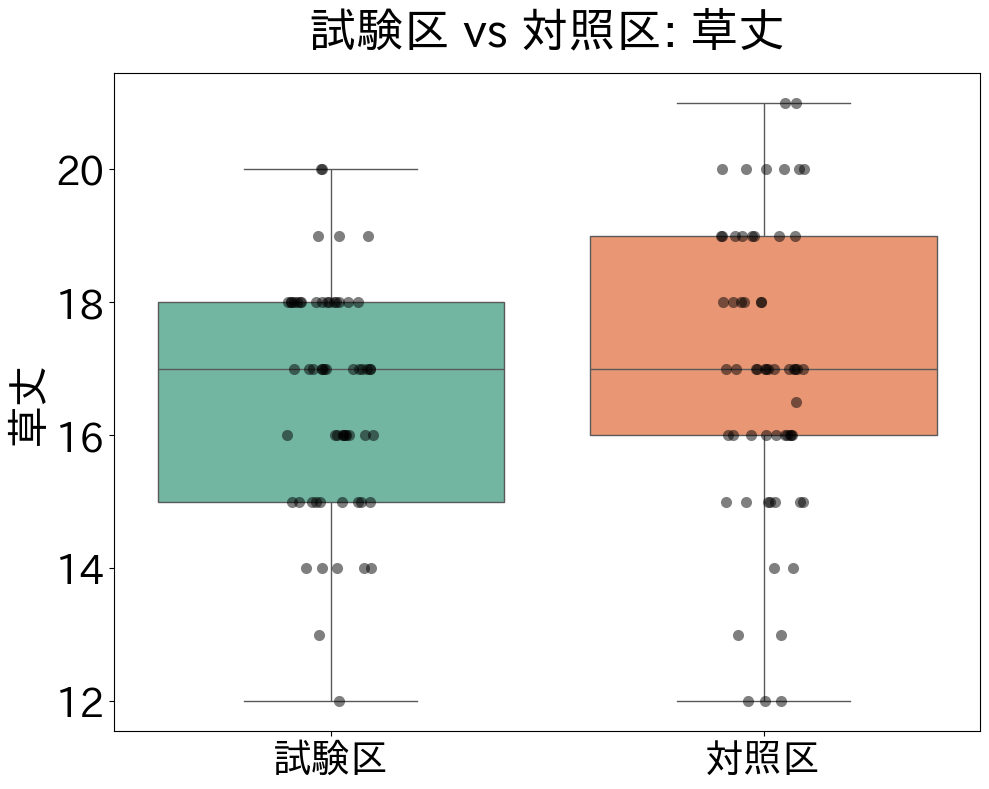

グラフを保存しました: graph_球重量.png


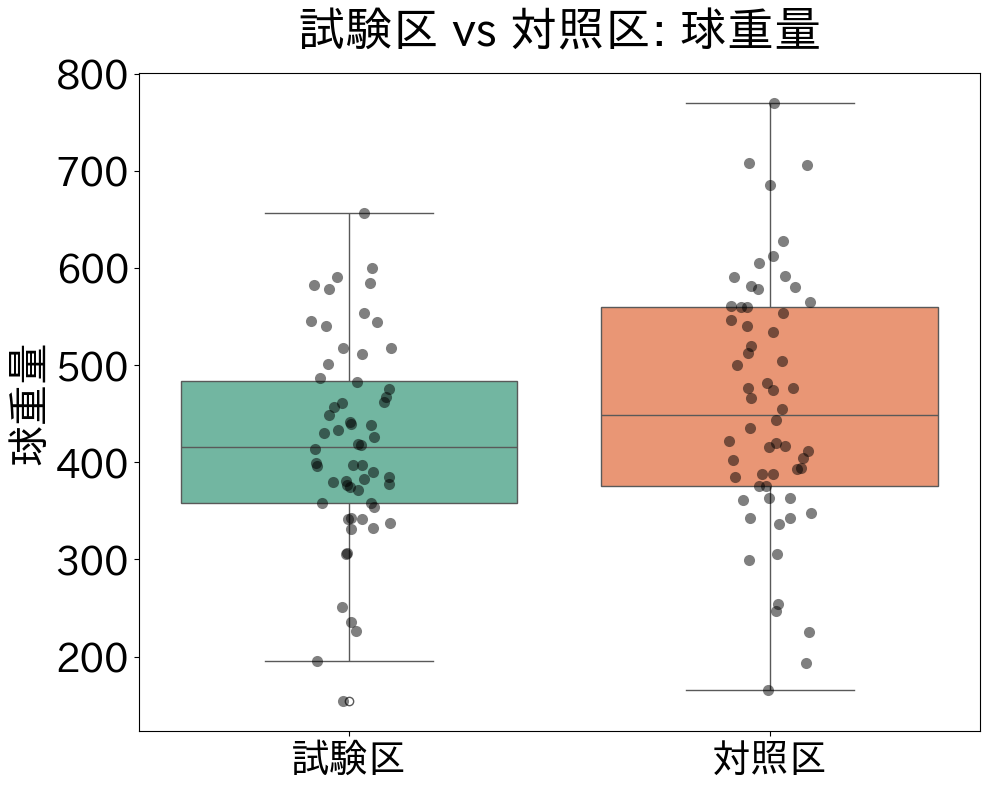

グラフを保存しました: graph_食害葉数_全部.png


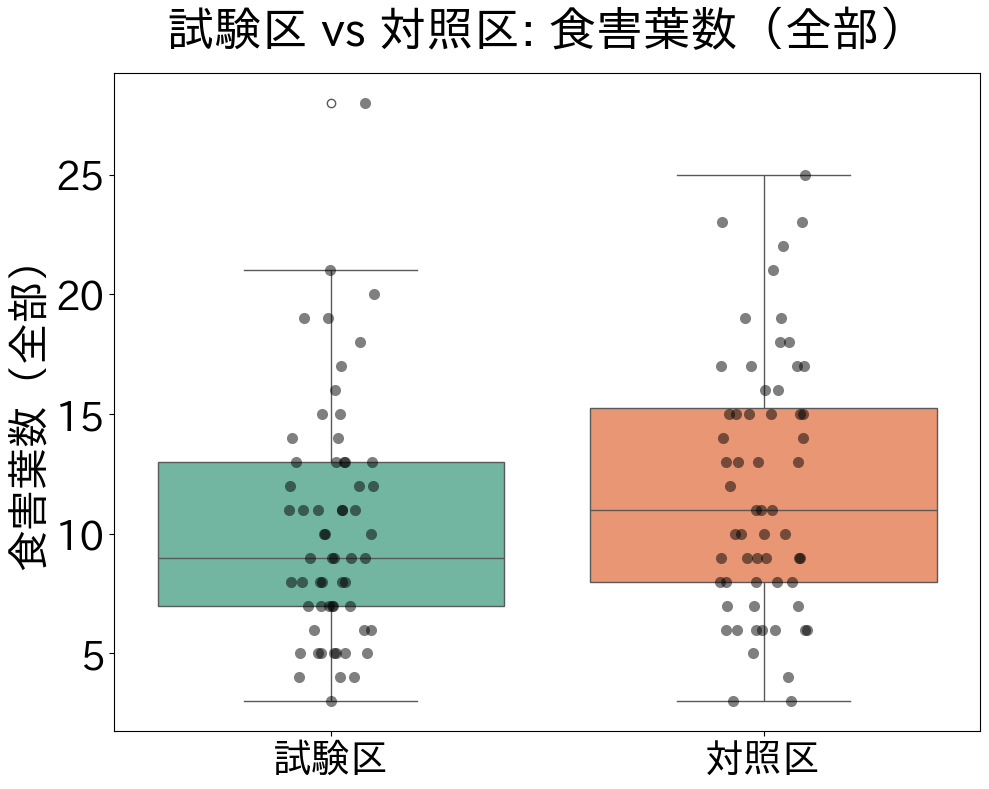

グラフを保存しました: graph_食害葉数_内.png


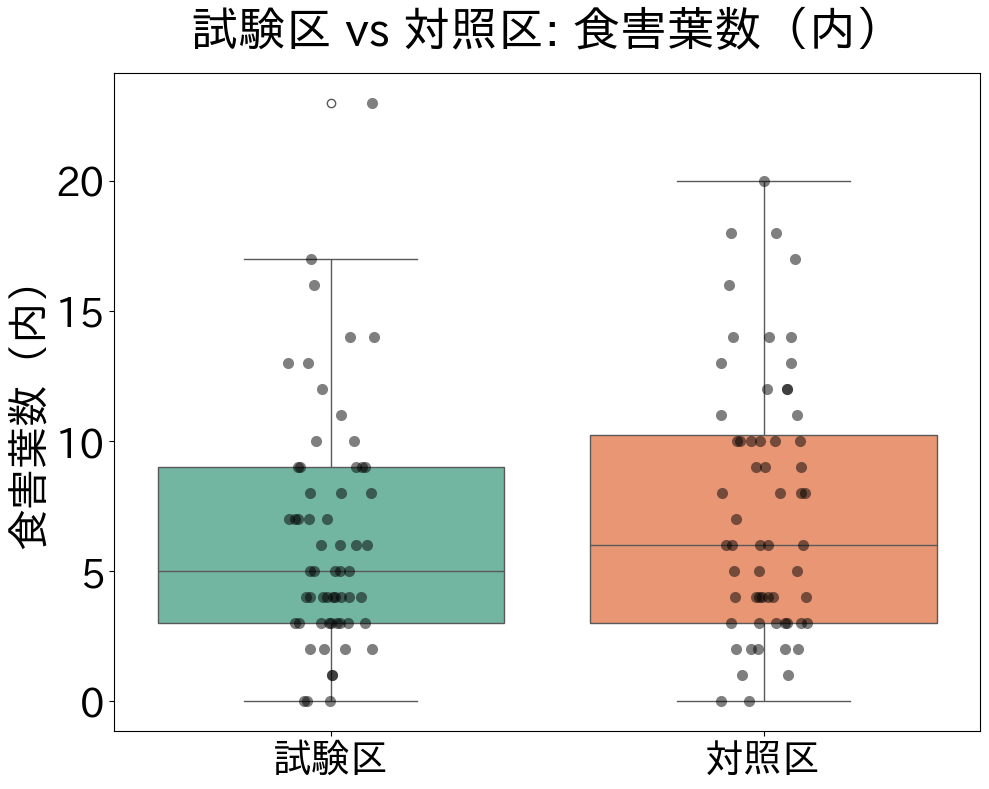

,虫の種類,試験区 合計(個),試験区 平均±SD,試験区 付着率(%),対照区 合計(個),対照区 平均±SD,対照区 付着率(%),p値(t検定),p値(付着率),有意差(p<0.05)
0,ヨトウ,35,0.58 ± 0.65,50.0%,30,0.50 ± 0.65,41.7%,0.4827,0.4638,なし
1,テントウ,3,0.05 ± 0.22,5.0%,4,0.07 ± 0.31,5.0%,0.7357,1.0000,なし
2,オオタバコガ,0,0.00 ± 0.00,0.0%,3,0.05 ± 0.22,5.0%,0.0832,0.2437,なし
3,アブラムシ,2,0.03 ± 0.18,3.3%,1,0.02 ± 0.13,1.7%,0.5627,1.0000,なし
4,卵合計,40,0.67 ± 0.68,55.0%,38,0.63 ± 0.84,46.7%,0.8121,0.4653,なし


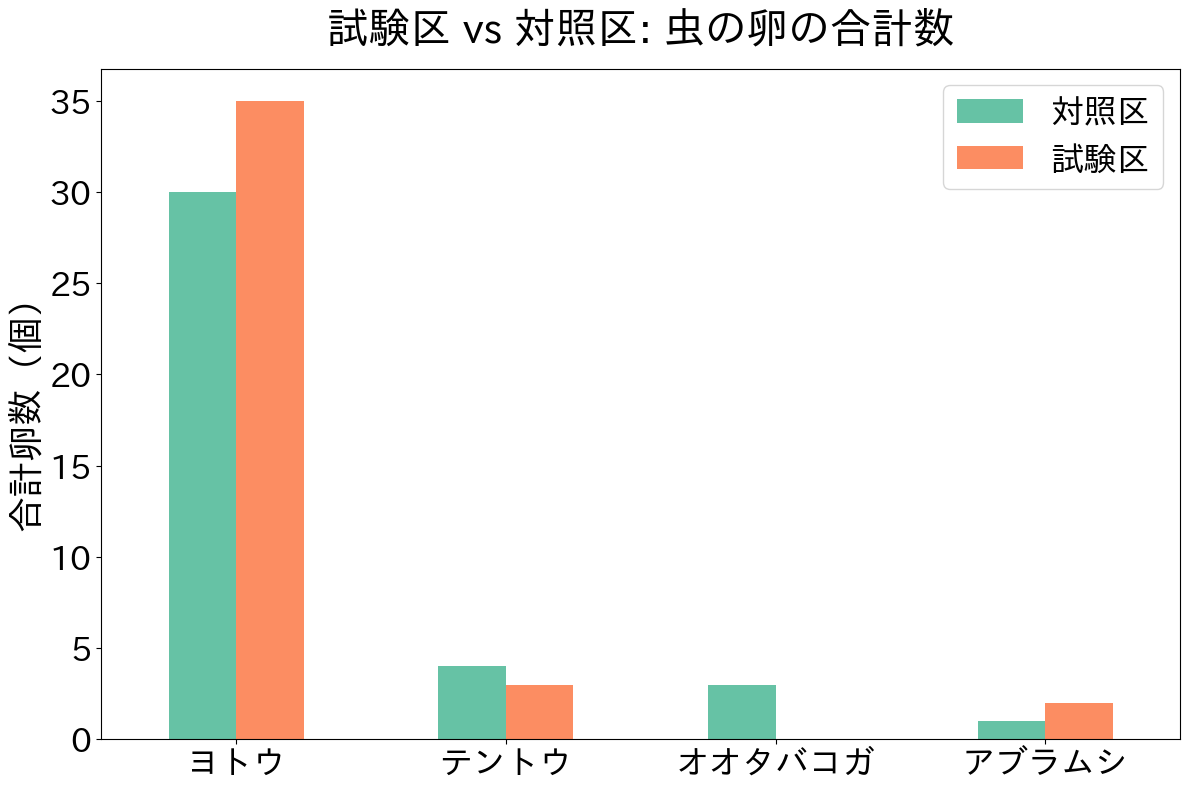


--- 虫の卵 分析結果サマリー ---


,卵の種類,試験区 合計,試験区 平均±SD,対照区 合計,対照区 平均±SD,p値,有意差 (p<0.05)
0,ヨトウ,35,0.58 ± 0.65,30,0.50 ± 0.65,0.4827,なし
1,テントウ,3,0.05 ± 0.22,4,0.07 ± 0.31,0.7357,なし
2,オオタバコガ,0,0.00 ± 0.00,3,0.05 ± 0.22,0.0832,なし
3,アブラムシ,2,0.03 ± 0.18,1,0.02 ± 0.13,0.5627,なし
4,卵合計,40,0.67 ± 0.68,38,0.63 ± 0.84,0.8121,なし


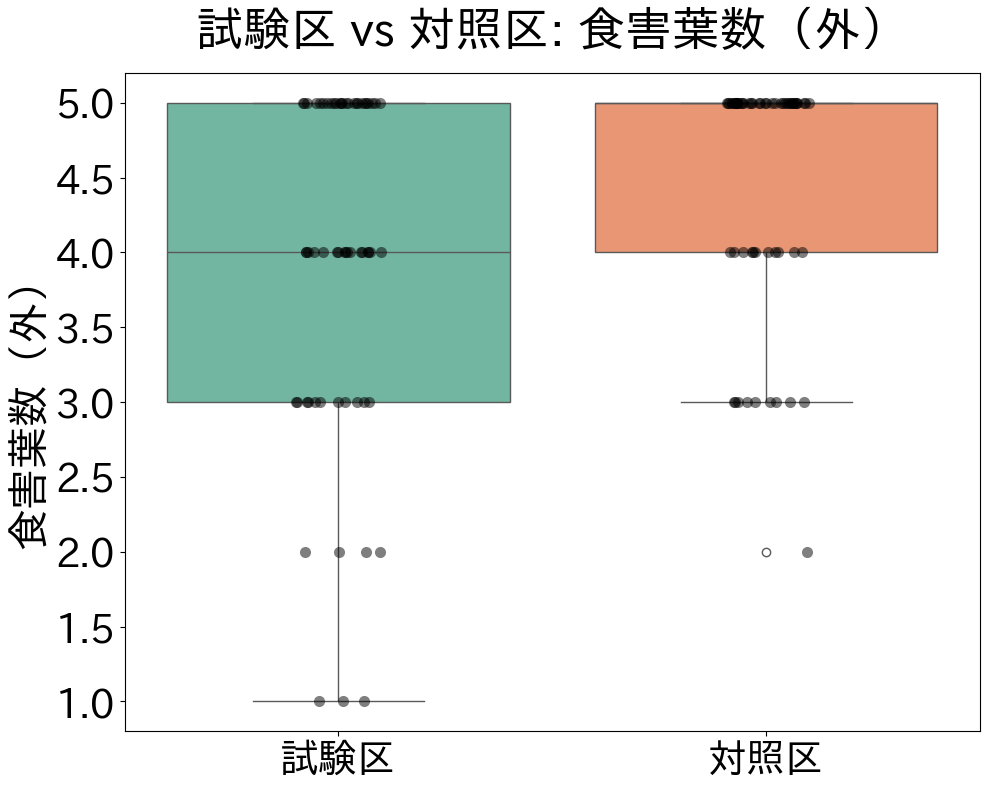

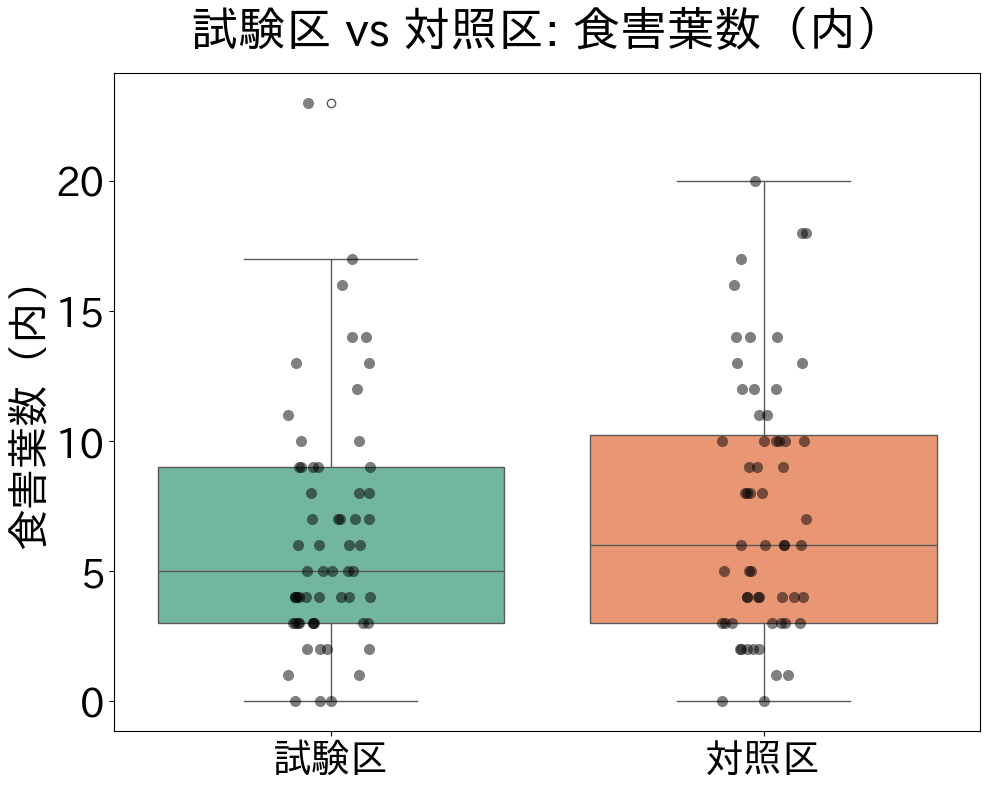

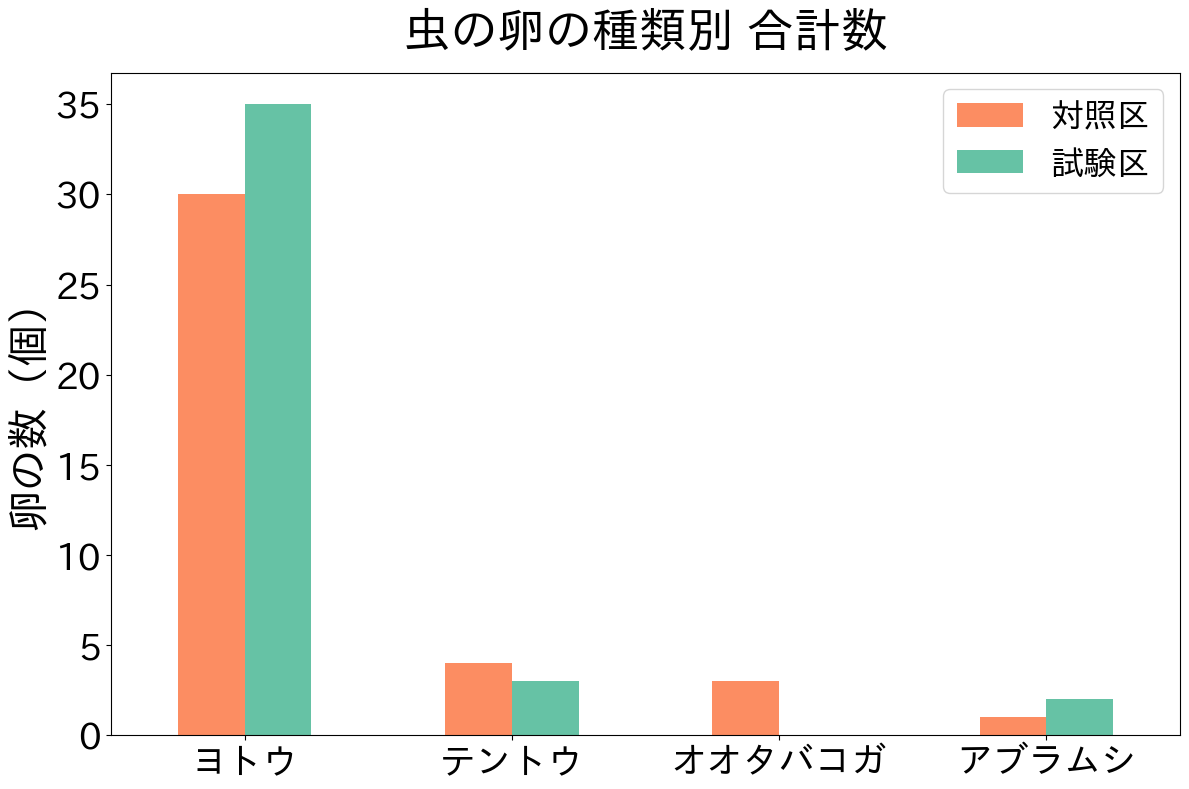

In [10]:
# Google Colab用：日本語フォント設定（初回のみインストールされます）
!pip install -q japanize-matplotlib

import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import japanize_matplotlib  # 日本語表示を有効化

# 1. データの読み込み（文字コードはcp932を指定）
file_path = 'result.csv'
df_raw = pd.read_csv(file_path, encoding='cp932', header=None)

# 2. データ構造（ブロック構造）に合わせたパース処理
parsed_data = []
block_rows = [0, 21, 42]      # 区のブロックが始まる行インデックス
col_starts = [0, 10, 20, 30]  # 区のブロックが始まる列インデックス

for r in block_rows:
    for c in col_starts:
        zone_name = df_raw.iloc[r, c]
        if pd.notna(zone_name) and '区' in str(zone_name):
            # ヘッダーの2行下から18株分を抽出
            sub = df_raw.iloc[r+2 : r+20, c:c+10].copy()
            sub.columns = ['株番号', '草丈', '葉数（外）', '葉数（内）', '球縦径', '球横径', '球重量', '食害葉数（外）', '食害葉数（内）', '備考']
            sub['区名'] = str(zone_name).strip()
            parsed_data.append(sub)

df_all = pd.concat(parsed_data, ignore_index=True)

# 数値型に変換
numeric_cols = ['草丈', '葉数（外）', '葉数（内）', '球縦径', '球横径', '球重量', '食害葉数（外）', '食害葉数（内）']
for col in numeric_cols:
    df_all[col] = pd.to_numeric(df_all[col], errors='coerce')

# 株番号が有効なデータのみ抽出
df_all = df_all.dropna(subset=['株番号'])

# 3. 試験区と対照区のグループ分け（「区」を除き、ハイフンを統一して判定）
def classify_group(zone):
    z = str(zone).strip().replace('区', '').replace('-', 'ー')
    test_list = ['①ー１', '①ー３', '②ー２', '③ー１', '③ー３', '④ー２']
    control_list = ['①ー２', '②ー１', '②ー３', '③ー２', '④ー１', '④ー３']
    if z in test_list:
        return '試験区'
    elif z in control_list:
        return '対照区'
    return 'その他'

df_all['グループ'] = df_all['区名'].apply(classify_group)
df_analysis = df_all[df_all['グループ'].isin(['試験区', '対照区'])].copy()

# 4. 指標の作成：食害葉数（全部） ＝ 食害葉数（外） ＋ 食害葉数（内）
df_analysis['食害葉数（全部）'] = df_analysis['食害葉数（外）'] + df_analysis['食害葉数（内）']

print("--- データ確認 ---")
print(f"抽出された全株数: {len(df_analysis)} 行")
print(df_analysis['グループ'].value_counts())

# ==========================================
# 5. 統計分析の実行 ＆ 結果のCSV保存
# ==========================================
target_metrics = ['草丈', '葉数（外）', '葉数（内）', '球縦径', '球横径', '球重量', '食害葉数（全部）', '食害葉数（内）']
results = []

for metric in target_metrics:
    test_vals = df_analysis[df_analysis['グループ'] == '試験区'][metric].dropna()
    control_vals = df_analysis[df_analysis['グループ'] == '対照区'][metric].dropna()

    if len(test_vals) > 1 and len(control_vals) > 1:
        test_mean, test_std = test_vals.mean(), test_vals.std()
        control_mean, control_std = control_vals.mean(), control_vals.std()

        # ウェルチのt検定
        t_stat, p_val = stats.ttest_ind(test_vals, control_vals, equal_var=False)

        results.append({
            '調査項目': metric,
            '試験区 (n)': len(test_vals),
            '試験区 平均±SD': f"{test_mean:.2f} ± {test_std:.2f}",
            '対照区 (n)': len(control_vals),
            '対照区 平均±SD': f"{control_mean:.2f} ± {control_std:.2f}",
            'p値': f"{p_val:.4f}" if pd.notna(p_val) else '-',
            '有意差 (p<0.05)': 'あり' if (pd.notna(p_val) and p_val < 0.05) else 'なし'
        })

df_results = pd.DataFrame(results)
print("\n--- 分析結果サマリー ---")
display(df_results)

# 表をCSVファイルとして保存（Excelで開いても文字化けしない utf-8-sig を指定）
csv_filename = 'analysis_summary.csv'
df_results.to_csv(csv_filename, index=False, encoding='utf-8-sig')
print(f"表を保存しました: {csv_filename}")


# ==========================================
# 6. 可視化（個別出力・文字サイズ3倍・画像保存）
# ==========================================
# 保存用のファイル名マッピング
plot_metrics = {
    '草丈': 'graph_草丈.png',
    '球重量': 'graph_球重量.png',
    '食害葉数（全部）': 'graph_食害葉数_全部.png',
    '食害葉数（内）': 'graph_食害葉数_内.png'
}

for metric, img_filename in plot_metrics.items():
    plt.figure(figsize=(10, 8))

    sns.boxplot(x='グループ', y=metric, data=df_analysis, hue='グループ', palette="Set2", legend=False)
    sns.stripplot(x='グループ', y=metric, data=df_analysis, color='black', alpha=0.5, jitter=True, size=8)

    plt.title(f'試験区 vs 対照区: {metric}', fontsize=34, pad=20)
    plt.xlabel('', fontsize=30)
    plt.ylabel(metric, fontsize=30)
    plt.xticks(fontsize=28)
    plt.yticks(fontsize=28)

    plt.tight_layout()

    # 個別の画像ファイルとして保存（plt.show() の前に実行するのがポイント）
    plt.savefig(img_filename, dpi=300, bbox_inches='tight')
    print(f"グラフを保存しました: {img_filename}")

    plt.show()
# ==========================================
# 7. 虫の卵の集計と試験区・対照区の比較
# ==========================================
# 有効調査株（草丈などが記録されている株）を抽出
df_valid = df_analysis.dropna(subset=['草丈']).copy()

insects = ['ヨトウ', 'テントウ', 'オオタバコガ', 'アブラムシ']
for ins in insects:
    df_valid[ins] = df_valid['備考'].fillna('').apply(lambda x: str(x).count(ins))
df_valid['卵合計'] = df_valid[insects].sum(axis=1)

egg_results = []
for ins in insects + ['卵合計']:
    t_vals = df_valid[df_valid['グループ'] == '試験区'][ins]
    c_vals = df_valid[df_valid['グループ'] == '対照区'][ins]
    t_pos, c_pos = (t_vals > 0).sum(), (c_vals > 0).sum()

    _, p_ttest = stats.ttest_ind(t_vals, c_vals, equal_var=False)
    _, p_fisher = stats.fisher_exact([[t_pos, len(t_vals)-t_pos], [c_pos, len(c_vals)-c_pos]])

    egg_results.append({
        '虫の種類': ins,
        '試験区 合計(個)': t_vals.sum(),
        '試験区 平均±SD': f"{t_vals.mean():.2f} ± {t_vals.std():.2f}",
        '試験区 付着率(%)': f"{t_pos/len(t_vals)*100:.1f}%",
        '対照区 合計(個)': c_vals.sum(),
        '対照区 平均±SD': f"{c_vals.mean():.2f} ± {c_vals.std():.2f}",
        '対照区 付着率(%)': f"{c_pos/len(c_vals)*100:.1f}%",
        'p値(t検定)': f"{p_ttest:.4f}",
        'p値(付着率)': f"{p_fisher:.4f}",
        '有意差(p<0.05)': 'あり' if p_ttest < 0.05 else 'なし'
    })

df_egg_results = pd.DataFrame(egg_results)
display(df_egg_results)
df_egg_results.to_csv('egg_analysis_summary.csv', index=False, encoding='utf-8-sig')

# 虫の種類別・合計卵数の棒グラフ
df_egg_sum = df_valid.groupby('グループ')[insects].sum().T
ax = df_egg_sum.plot(kind='bar', figsize=(12, 8), color=['#66c2a5', '#fc8d62'], rot=0)
plt.title('試験区 vs 対照区: 虫の卵の合計数', fontsize=30, pad=20)
plt.ylabel('合計卵数（個）', fontsize=26)
plt.xticks(fontsize=24)
plt.yticks(fontsize=24)
plt.legend(fontsize=24)
plt.tight_layout()
plt.savefig('graph_虫の卵.png', dpi=300, bbox_inches='tight')
plt.show()
# ==========================================
# 7. 虫の卵の分析（備考欄のカウント）
# ==========================================
pests = ['ヨトウ', 'テントウ', 'オオタバコガ', 'アブラムシ']

# 調査データがある有効株（食害葉数（外）が欠損でない株）を対象にする
df_valid = df_analysis.dropna(subset=['食害葉数（外）']).copy()

# 各株ごとに文字列の出現回数をカウント（1セルに複数記載がある場合も正確にカウント）
for p in pests:
    df_valid[p] = df_valid['備考'].fillna('').astype(str).apply(lambda x: x.count(p))

df_valid['卵合計'] = df_valid[pests].sum(axis=1)

# 卵の統計分析
egg_results = []
for p in pests + ['卵合計']:
    t_vals = df_valid[df_valid['グループ'] == '試験区'][p]
    c_vals = df_valid[df_valid['グループ'] == '対照区'][p]
    t_stat, p_val = stats.ttest_ind(t_vals, c_vals, equal_var=False)

    egg_results.append({
        '卵の種類': p,
        '試験区 合計': int(t_vals.sum()),
        '試験区 平均±SD': f"{t_vals.mean():.2f} ± {t_vals.std():.2f}",
        '対照区 合計': int(c_vals.sum()),
        '対照区 平均±SD': f"{c_vals.mean():.2f} ± {c_vals.std():.2f}",
        'p値': f"{p_val:.4f}" if pd.notna(p_val) else '-',
        '有意差 (p<0.05)': 'あり' if (pd.notna(p_val) and p_val < 0.05) else 'なし'
    })

df_egg_results = pd.DataFrame(egg_results)
print("\n--- 虫の卵 分析結果サマリー ---")
display(df_egg_results)
df_egg_results.to_csv('egg_analysis_summary.csv', index=False, encoding='utf-8-sig')


# ==========================================
# 8. 食害葉数（外葉・内葉）の個別グラフ作成・保存
# ==========================================
damage_metrics = {
    '食害葉数（外）': 'graph_食害葉数_外.png',
    '食害葉数（内）': 'graph_食害葉数_内.png'
}

for metric, img_filename in damage_metrics.items():
    plt.figure(figsize=(10, 8))
    sns.boxplot(x='グループ', y=metric, data=df_valid, hue='グループ', palette="Set2", legend=False)
    sns.stripplot(x='グループ', y=metric, data=df_valid, color='black', alpha=0.5, jitter=True, size=8)

    plt.title(f'試験区 vs 対照区: {metric}', fontsize=34, pad=20)
    plt.xlabel('', fontsize=30)
    plt.ylabel(metric, fontsize=30)
    plt.xticks(fontsize=28)
    plt.yticks(fontsize=28)
    plt.tight_layout()

    plt.savefig(img_filename, dpi=300, bbox_inches='tight')
    plt.show()

# 虫の卵の合計数の比較グラフ（棒グラフ：種類別合計）
df_egg_sum = df_valid.groupby('グループ')[pests].sum().T
ax = df_egg_sum.plot(kind='bar', figsize=(12, 8), color=['#fc8d62', '#66c2a5'], rot=0)
plt.title('虫の卵の種類別 合計数', fontsize=34, pad=20)
plt.ylabel('卵の数（個）', fontsize=30)
plt.xticks(fontsize=26)
plt.yticks(fontsize=26)
plt.legend(fontsize=24)
plt.tight_layout()
plt.savefig('graph_虫の卵_合計.png', dpi=300, bbox_inches='tight')
plt.show()

In [11]:
import pandas as pd
import numpy as np
from scipy import stats

# 1. データの読み込み
file_path = 'result.csv'
df_raw = pd.read_csv(file_path, encoding='cp932', header=None)

# 2. パース処理
parsed_data = []
block_rows = [0, 21, 42]
col_starts = [0, 10, 20, 30]

for r in block_rows:
    for c in col_starts:
        zone_name = df_raw.iloc[r, c]
        if pd.notna(zone_name) and '区' in str(zone_name):
            sub = df_raw.iloc[r+2 : r+20, c:c+10].copy()
            sub.columns = ['株番号', '草丈', '葉数（外）', '葉数（内）', '球縦径', '球横径', '球重量', '食害葉数（外）', '食害葉数（内）', '備考']
            sub['区名'] = str(zone_name).strip()
            parsed_data.append(sub)

df_all = pd.concat(parsed_data, ignore_index=True)

# 数値型へ変換
numeric_cols = ['草丈', '葉数（外）', '葉数（内）', '球縦径', '球横径', '球重量', '食害葉数（外）', '食害葉数（内）']
for col in numeric_cols:
    df_all[col] = pd.to_numeric(df_all[col], errors='coerce')

df_all = df_all.dropna(subset=['株番号'])

# 3. グループ分け
def classify_group(zone):
    z = str(zone).strip().replace('区', '').replace('-', 'ー')
    test_list = ['①ー１', '①ー３', '②ー２', '③ー１', '③ー３', '④ー２']
    control_list = ['①ー２', '②ー１', '②ー３', '③ー２', '④ー１', '④ー３']
    if z in test_list:
        return '試験区'
    elif z in control_list:
        return '対照区'
    return 'その他'

df_all['グループ'] = df_all['区名'].apply(classify_group)
df_analysis = df_all[df_all['グループ'].isin(['試験区', '対照区'])].copy()
df_analysis['食害葉数（全部）'] = df_analysis['食害葉数（外）'] + df_analysis['食害葉数（内）']

# 4. 統計分析（食害葉数（外）を追加した順序で定義）
target_metrics = ['草丈', '葉数（外）', '葉数（内）', '球縦径', '球横径', '球重量', '食害葉数（全部）', '食害葉数（外）', '食害葉数（内）']
results = []

for metric in target_metrics:
    test_vals = df_analysis[df_analysis['グループ'] == '試験区'][metric].dropna()
    control_vals = df_analysis[df_analysis['グループ'] == '対照区'][metric].dropna()

    if len(test_vals) > 1 and len(control_vals) > 1:
        test_mean, test_std = test_vals.mean(), test_vals.std()
        control_mean, control_std = control_vals.mean(), control_vals.std()

        # ウェルチのt検定
        t_stat, p_val = stats.ttest_ind(test_vals, control_vals, equal_var=False)

        results.append({
            '調査項目': metric,
            '試験区 (n)': len(test_vals),
            '試験区 平均±SD': f"{test_mean:.2f} ± {test_std:.2f}",
            '対照区 (n)': len(control_vals),
            '対照区 平均±SD': f"{control_mean:.2f} ± {control_std:.2f}",
            'p値': f"{p_val:.4f}" if pd.notna(p_val) else '-',
            '有意差 (p<0.05)': 'あり' if (pd.notna(p_val) and p_val < 0.05) else 'なし'
        })
    else:
        results.append({
            '調査項目': metric,
            '試験区 (n)': len(test_vals),
            '試験区 平均±SD': 'データ不足',
            '対照区 (n)': len(control_vals),
            '対照区 平均±SD': 'データ不足',
            'p値': '-',
            '有意差 (p<0.05)': '-'
        })

df_results = pd.DataFrame(results)

# 5. 結果の表示とCSV保存
print("\n--- 更新された分析結果サマリー ---")
display(df_results)

csv_filename = 'analysis_summary.csv'
df_results.to_csv(csv_filename, index=False, encoding='utf-8-sig')
print(f"'{csv_filename}' を更新して保存しました。")


--- 更新された分析結果サマリー ---


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


,調査項目,試験区 (n),試験区 平均±SD,対照区 (n),対照区 平均±SD,p値,有意差 (p<0.05)
0,草丈,60,16.60 ± 1.69,60,16.91 ± 2.20,0.3917,なし
1,葉数（外）,60,5.00 ± 0.00,60,5.00 ± 0.00,-,なし
2,葉数（内）,60,21.15 ± 4.06,60,21.63 ± 4.75,0.5502,なし
3,球縦径,60,36.78 ± 4.52,60,37.53 ± 5.26,0.4037,なし
4,球横径,60,37.78 ± 3.70,60,38.07 ± 4.22,0.6963,なし
5,球重量,60,420.01 ± 103.36,60,459.00 ± 129.47,0.0710,なし
6,食害葉数（全部）,60,10.27 ± 4.97,60,11.92 ± 5.39,0.0841,なし
7,食害葉数（外）,60,3.95 ± 1.16,60,4.47 ± 0.81,0.0055,あり
8,食害葉数（内）,60,6.32 ± 4.56,60,7.45 ± 4.98,0.1963,なし


'analysis_summary.csv' を更新して保存しました。


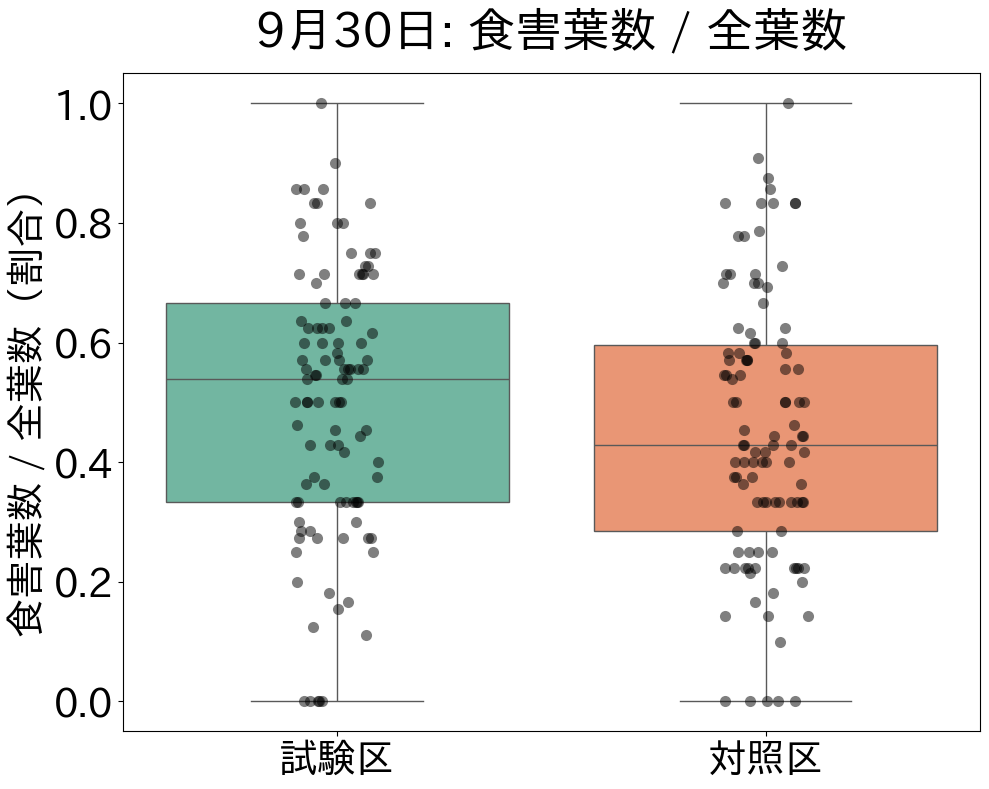

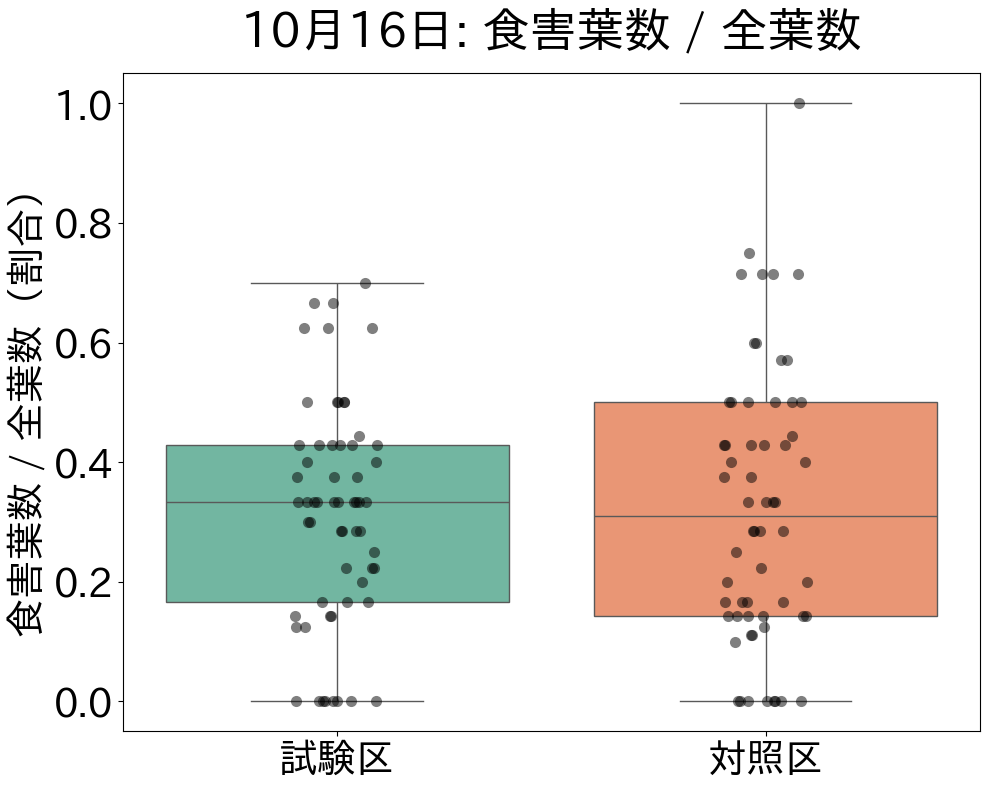

--- 分析①：食害葉数/全葉数 サマリー ---


,調査日,試験区 (n),試験区 平均±SD,対照区 (n),対照区 平均±SD,p値,有意差 (p<0.05)
0,9月30日,104,0.5007 ± 0.2251,106,0.4509 ± 0.2265,0.1116,なし
1,10月16日,60,0.3120 ± 0.1862,60,0.3234 ± 0.2315,0.7662,なし



--- 分析②：9月30日 虫の種類 サマリー ---


,虫の種類,試験区 合計,試験区 平均±SD,対照区 合計,対照区 平均±SD,p値,有意差 (p<0.05)
0,ウワバ,104,17.33 ± 6.28,68,11.33 ± 5.54,0.1103,なし
1,ヨトウ,0,0.00 ± 0.00,0,0.00 ± 0.00,-,なし（両区とも0）


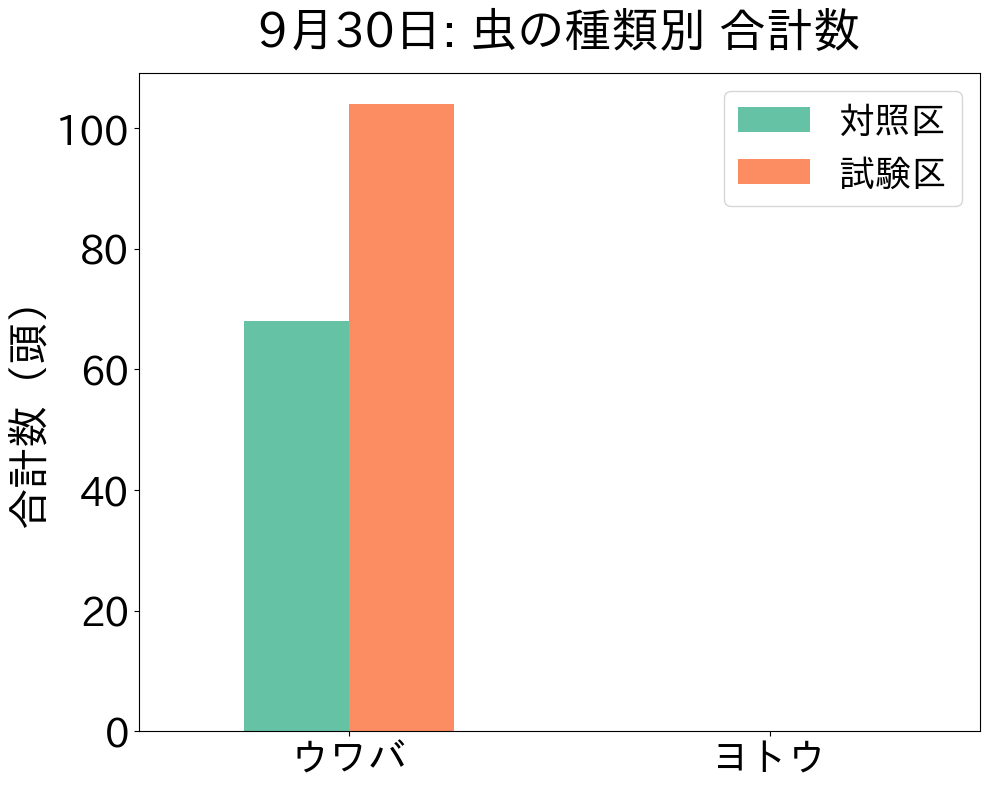

In [9]:
# Google Colab用：日本語フォント設定
!pip install -q japanize-matplotlib

import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import japanize_matplotlib

# 1. データの読み込み
file_path = 'result2.csv'
df_raw = pd.read_csv(file_path, encoding='cp932', header=None)

# 2. データのパース（9月30日・10月16日の「食害葉数/全葉数」）
records = []
for date_label, start_r in [('10月16日', 0), ('9月30日', 23)]:
    for col_start in range(0, 32, 8):
        zone_base = str(df_raw.iloc[start_r, col_start]).strip().replace('区', '')
        for r in range(start_r + 2, start_r + 20):
            plant_num = df_raw.iloc[r, col_start]
            remark = df_raw.iloc[r, col_start + 7]
            for sub_idx in range(1, 7):
                val = df_raw.iloc[r, col_start + sub_idx]
                if pd.notna(val) and '/' in str(val):
                    records.append({
                        '調査日': date_label,
                        '大区': zone_base,
                        '枝番': sub_idx,
                        '株番号': plant_num,
                        '食害_全葉': str(val).strip(),
                        '備考': remark
                    })

df_parsed = pd.DataFrame(records)

# 3. 試験区・対照区のグループ分け（10月16日の列4,5,6はそれぞれ1,2,3に対応）
num_to_zen = {1: '１', 2: '２', 3: '３', 4: '１', 5: '２', 6: '３'}
test_zones = ['①ー１', '①ー３', '②ー２', '③ー１', '③ー３', '④ー２']
control_zones = ['①ー２', '②ー１', '②ー３', '③ー２', '④ー１', '④ー３']

df_parsed['区名'] = df_parsed['大区'] + 'ー' + df_parsed['枝番'].map(num_to_zen)
df_parsed['グループ'] = df_parsed['区名'].apply(
    lambda z: '試験区' if z in test_zones else ('対照区' if z in control_zones else 'その他')
)

# 4. 「食害葉数/全葉数」の数値変換
def parse_ratio(val):
    p = str(val).split('/')
    d, t = float(p[0]), float(p[1])
    return d, t, (d / t if t > 0 else np.nan)

res = df_parsed['食害_全葉'].apply(parse_ratio)
df_parsed['食害葉数'] = [r[0] for r in res]
df_parsed['全葉数'] = [r[1] for r in res]
df_parsed['食害割合'] = [r[2] for r in res]

# ==========================================
# 分析①：試験区 vs 対照区（食害葉数 / 全葉数）
# ==========================================
summary_ratio = []
for date_val in ['9月30日', '10月16日']:
    sub = df_parsed[df_parsed['調査日'] == date_val]
    t_vals = sub[sub['グループ'] == '試験区']['食害割合'].dropna()
    c_vals = sub[sub['グループ'] == '対照区']['食害割合'].dropna()

    _, p_val = stats.ttest_ind(t_vals, c_vals, equal_var=False)
    summary_ratio.append({
        '調査日': date_val,
        '試験区 (n)': len(t_vals),
        '試験区 平均±SD': f"{t_vals.mean():.4f} ± {t_vals.std():.4f}",
        '対照区 (n)': len(c_vals),
        '対照区 平均±SD': f"{c_vals.mean():.4f} ± {c_vals.std():.4f}",
        'p値': f"{p_val:.4f}",
        '有意差 (p<0.05)': 'あり' if p_val < 0.05 else 'なし'
    })

    # 個別グラフ出力・保存（文字サイズ約3倍）
    plt.figure(figsize=(10, 8))
    sns.boxplot(x='グループ', y='食害割合', data=sub, hue='グループ', palette="Set2", legend=False)
    sns.stripplot(x='グループ', y='食害割合', data=sub, color='black', alpha=0.5, jitter=True, size=8)
    plt.title(f'{date_val}: 食害葉数 / 全葉数', fontsize=34, pad=20)
    plt.xlabel('', fontsize=30)
    plt.ylabel('食害葉数 / 全葉数（割合）', fontsize=28)
    plt.xticks(fontsize=28)
    plt.yticks(fontsize=28)
    plt.tight_layout()
    plt.savefig(f'graph_食害割合_{date_val}.png', dpi=300, bbox_inches='tight')
    plt.show()

df_summary_ratio = pd.DataFrame(summary_ratio)
print("--- 分析①：食害葉数/全葉数 サマリー ---")
display(df_summary_ratio)
df_summary_ratio.to_csv('result2_食害割合サマリー.csv', index=False, encoding='utf-8-sig')


# ==========================================
# 分析②：9月30日 虫の種類（ウワバ・ヨトウ）の比較
# ==========================================
insect_records = []
for col_start in range(0, 32, 8):
    zone_base = str(df_raw.iloc[23, col_start]).strip().replace('区', '')
    for sub_idx in range(1, 4):
        zone_name = f"{zone_base}ー{num_to_zen[sub_idx]}"
        group = '試験区' if zone_name in test_zones else '対照区'
        uwaba = float(str(df_raw.iloc[43, col_start + sub_idx]).strip())
        yotou = float(str(df_raw.iloc[44, col_start + sub_idx]).strip())
        insect_records.append({'区名': zone_name, 'グループ': group, 'ウワバ': uwaba, 'ヨトウ': yotou})

df_insects = pd.DataFrame(insect_records)

insect_summary = []
for ins in ['ウワバ', 'ヨトウ']:
    t_i = df_insects[df_insects['グループ'] == '試験区'][ins]
    c_i = df_insects[df_insects['グループ'] == '対照区'][ins]
    if t_i.sum() > 0 or c_i.sum() > 0:
        _, p_i = stats.ttest_ind(t_i, c_i, equal_var=False)
        p_str = f"{p_i:.4f}"
        sig = 'あり' if p_i < 0.05 else 'なし'
    else:
        p_str, sig = '-', 'なし（両区とも0）'

    insect_summary.append({
        '虫の種類': ins,
        '試験区 合計': int(t_i.sum()),
        '試験区 平均±SD': f"{t_i.mean():.2f} ± {t_i.std():.2f}",
        '対照区 合計': int(c_i.sum()),
        '対照区 平均±SD': f"{c_i.mean():.2f} ± {c_i.std():.2f}",
        'p値': p_str,
        '有意差 (p<0.05)': sig
    })

df_insect_summary = pd.DataFrame(insect_summary)
print("\n--- 分析②：9月30日 虫の種類 サマリー ---")
display(df_insect_summary)
df_insect_summary.to_csv('result2_虫の種類サマリー.csv', index=False, encoding='utf-8-sig')

# 虫の種類の棒グラフ出力・保存（文字サイズ約3倍）
df_ins_plot = df_insects.groupby('グループ')[['ウワバ', 'ヨトウ']].sum().T
df_ins_plot.plot(kind='bar', figsize=(10, 8), color=['#66c2a5', '#fc8d62'], rot=0)
plt.title('9月30日: 虫の種類別 合計数', fontsize=34, pad=20)
plt.ylabel('合計数（頭）', fontsize=30)
plt.xticks(fontsize=28)
plt.yticks(fontsize=28)
plt.legend(fontsize=26)
plt.tight_layout()
plt.savefig('graph_9月30日_虫の種類.png', dpi=300, bbox_inches='tight')
plt.show()